# UnequalTime: demo

This notebook measures the unequal time power spectrum, $\mathcal Z_\ell(\omega)$, from a catalog of galaxies and compares it to the linear theory predictions.

We use a small test catalog (`data/catalog.npz`, made by `make_catalog.py`) containing Poisson-sampled galaxies from a Gaussian linear density field with bias $b(z) = 0.4 + 0.25z$ and Kaiser redshift-space distortions across a wavenumber range $k < 0.07\,h/{\rm Mpc}$ and $0.1 < z < 0.7$. We use a simple footprint with varying completeness (`data/mask.fits`).

In [13]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import unequaltime as ut

# Load catalog
cat = np.load('data/catalog.npz')
ra, dec, z = cat['ra'], cat['dec'], cat['z']
mask = hp.read_map('data/mask.fits')          # angular mask Omega(n), HEALPix (RING)
print(f'{len(z)} galaxies, nside {hp.npix2nside(len(mask))}')

1061627 galaxies, nside 64


## The survey

The `Survey` class defines the mask, the binning, the background density and the weights. Here, we'll use two redshift bins, 24 radial frequencies per bin in multiples of $\pi/\Delta z$ (the fundamental mode), and 15 $\ell$-bins up to $\ell \approx k_{\max}\chi(z=0.7)$, beyond which the catalog has no signal. With `nbar='data'`, the radial density, $\bar n(z)$, (which satisfies $\bar n_g(\hat{\mathbf{n}},z) = \bar n(z)\Omega(\hat{\mathbf{n}})$) is estimated from the galaxy catalog. This induces radial integral constraint corrections, which we include in the theory model.

Computing the mode-coupling matrices of the mask (nside 64)
Computing the radial integral constraint (192 harmonic transforms)
Redshift bin 0: assigning 499972 galaxies to the grid and transforming to 24 frequencies
Redshift bin 0: computing 48 spherical harmonic transforms and the power spectra
Redshift bin 1: assigning 561655 galaxies to the grid and transforming to 24 frequencies
Redshift bin 1: computing 48 spherical harmonic transforms and the power spectra
(2, 24, 15)


[Text(0.5, 0, '$z$'),
 Text(0, 0.5, '$\\bar n(z)$ [per unit $z$, per sr]'),
 Text(0.5, 1.0, 'background density and redshift bins')]

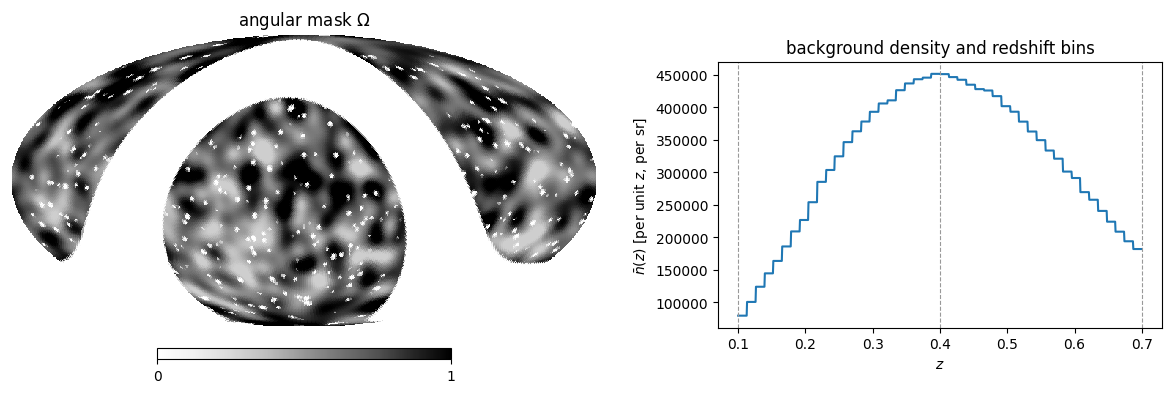

In [14]:
# Define the survey
survey = ut.Survey(mask, # observational mask
                   zbins=[0.1, 0.4, 0.7], # redshift bin edges
                   nomega=24, # number of radial frequencies (in units of the fundamental)
                   ell_edges=np.arange(2, 123, 8), # ell bin edges, up to kmax * chi(z = 0.7)
                   nbar='data', # n(z) [either set or estimated from the data]
                   w=None, # w(z) redshift weights
                   width=1,  # how many frequencies to include in each bin
                   pairs=False # whether to add Z_l(omega, omega') and Z_l(omega, -omega') cross-correlations
                  )

# Measure the unequal-time power spectrum 
Z_obs = survey.measure(ra, dec, z)                                    # Z_ell(omega): (redshift bin, omega, ell)
print(Z_obs.shape)

# Plot the mask and background density
fig = plt.figure(figsize=(12, 3.8))
hp.mollview(mask, title=r'angular mask $\Omega$', sub=(1, 2, 1), cmap='Greys', min=0, max=1)
ax = fig.add_axes([0.6, 0.15, 0.37, 0.7])
zz = np.linspace(0.1, 0.7, 1000)
ax.plot(zz, survey.nbar(zz), lw=1.5)                              # nbar(z) estimated from the catalog
for edge in survey.zbins:
    ax.axvline(edge, color='0.6', lw=0.8, ls='--')
ax.set(xlabel='$z$', ylabel=r'$\bar n(z)$ [per unit $z$, per sr]', title='background density and redshift bins')

## Theory and covariance

The `theory` function computes the unmasked linear theory for all frequencies specified in `Survey`. The `expected` function applies the mask and binning (via `namaster`), and `covariance` computes the Gaussian covariance of the measurement, including shot noise and correlations between frequencies and redshift bins.

In [15]:
# Compute the background cosmology (matching that used to generate the catalog)
from classy import Class
cl = Class()                                                      
cl.set({'h': 0.6766, 'omega_b': 0.02242, 'omega_cdm': 0.11933, 'n_s': 0.9665, 'ln10^{10}A_s': 3.047, 'output': 'mPk',
        'P_k_max_1/Mpc': 1.})
cl.compute()

# Compute the theory spectra and apply binning
spectra = survey.theory(cl, b=lambda x: 0.4 + 0.25 * x, kmax=0.07)
Z_th = survey.expected(spectra)

# Compute the Gaussian errorbars
cov = survey.covariance(spectra)
err = np.sqrt(cov.diagonal()).reshape(Z_obs.shape)

Computing the linear theory at 87 multipoles (k < 0.07 h/Mpc)
Computing the covariance of 720 elements before omega-binning


Below, we plot the angular power spectrum as a function of $\ell$ and $\omega$. Though the points are noisy (since we have included very few galaxies in the analysis and restricted the theory to large scales), we find good agreement between models and data. Note that $\mathcal Z_\ell(0)$ is proportional to the angular power spectrum of the bin, \textit{i.e.} $C_\ell$. 

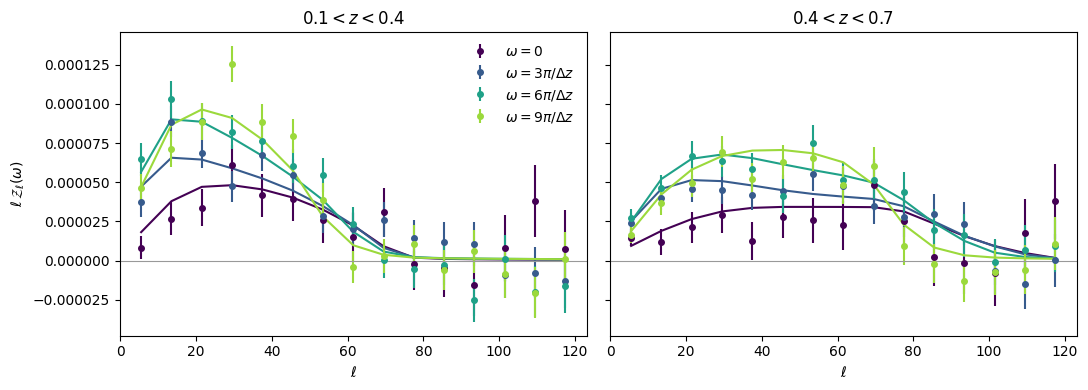

In [16]:
ell, omega = survey.ell, survey.omega
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, 4))
for ibin, ax in enumerate(axes):
    for color, m in zip(colors, (0, 3, 6, 9)):
        ax.errorbar(ell, ell * Z_obs[ibin, m], ell * err[ibin, m], fmt='o', ms=4, color=color,
                    label=rf'$\omega = {m}\pi/\Delta z$' if m else r'$\omega = 0$')
        ax.plot(ell, ell * Z_th[ibin, m], color=color, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set(xlabel=r'$\ell$', title=f'${survey.zbins[ibin]} < z < {survey.zbins[ibin + 1]}$')
axes[0].set_ylabel(r'$\ell\,\mathcal{Z}_\ell(\omega)$')
axes[0].legend(frameon=False)
plt.tight_layout()

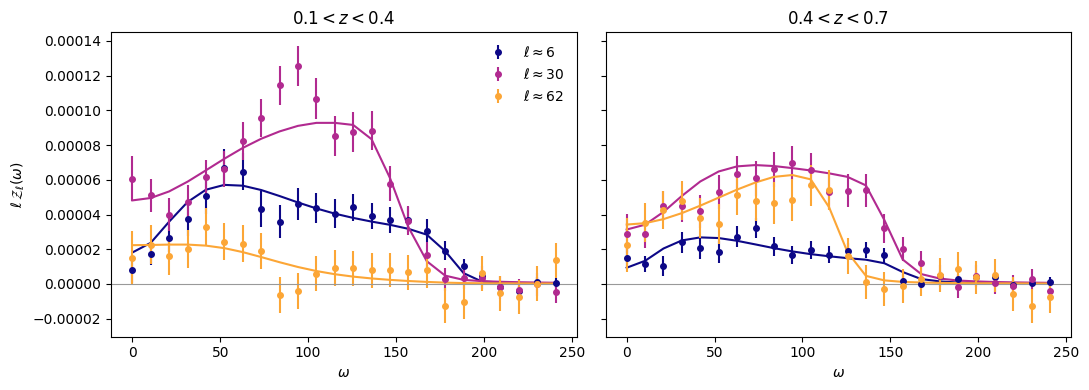

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = plt.cm.plasma(np.linspace(0, 0.8, 3))
for ibin, ax in enumerate(axes):
    for color, i in zip(colors, (0, 3, 7)):
        ax.errorbar(omega[ibin], ell[i] * Z_obs[ibin, :, i], ell[i] * err[ibin, :, i], fmt='o', ms=4, color=color,
                    label=rf'$\ell \approx {ell[i]:.0f}$')
        ax.plot(omega[ibin], ell[i] * Z_th[ibin, :, i], color=color, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set(xlabel=r'$\omega$', title=f'${survey.zbins[ibin]} < z < {survey.zbins[ibin + 1]}$')
axes[0].set_ylabel(r'$\ell\,\mathcal{Z}_\ell(\omega)$')
axes[0].legend(frameon=False)
plt.tight_layout()

We can also visualize the spectra in two dimensions. Note that $\mathcal{Z}_\ell(\omega)$ is asymptotically the flat-sky power spectrum $\frac{H}{c\chi^2}P_{gg}(k_\perp=\frac{\ell+1/2}{\chi}, k_\parallel = \frac{\omega H}{c}, z)$.

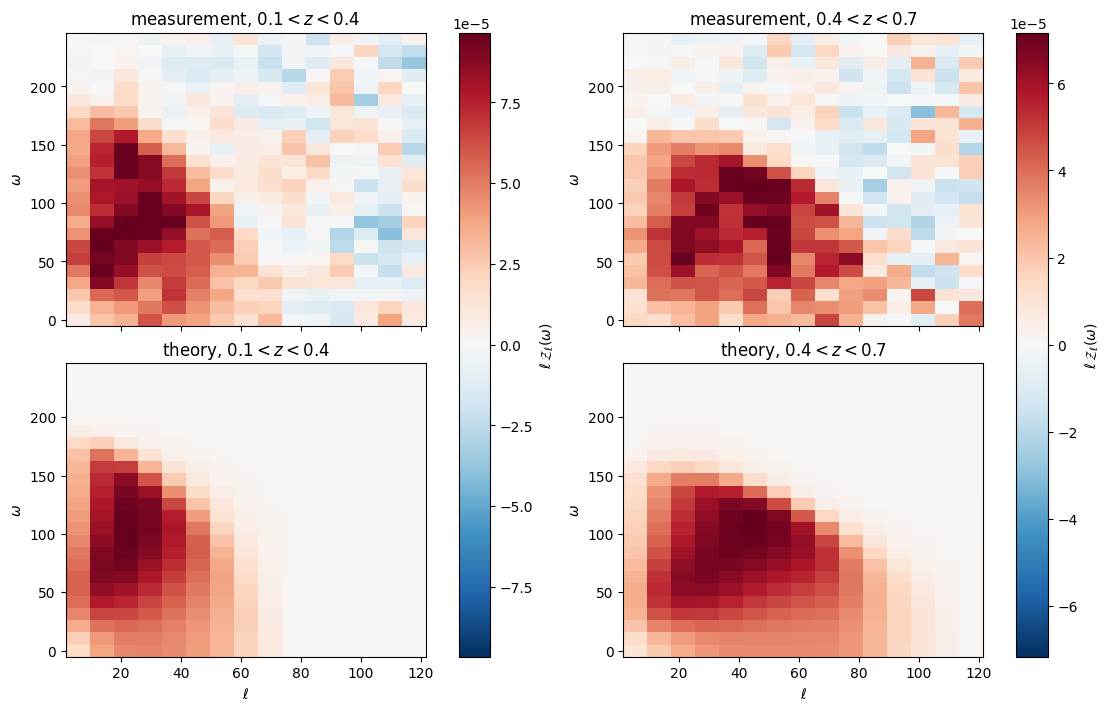

In [18]:
# Plot ell * Z_ell(omega) in the (ell, omega) plane: the signal is concentrated at k^2 ~ (ell / chi)^2 + (omega H)^2 < kmax^2
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, constrained_layout=True)
for ibin in range(2):
    vmax = np.abs(ell * Z_th[ibin]).max()
    for row, (x, title) in enumerate(((Z_obs, 'measurement'), (Z_th, 'theory'))):
        im = axes[row, ibin].pcolormesh(ell, omega[ibin], ell * x[ibin], shading='nearest', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        axes[row, ibin].set(ylabel=r'$\omega$', title=f'{title}, ${survey.zbins[ibin]} < z < {survey.zbins[ibin + 1]}$')
    axes[1, ibin].set_xlabel(r'$\ell$')
    fig.colorbar(im, ax=axes[:, ibin], label=r'$\ell\,\mathcal{Z}_\ell(\omega)$')

## Fitting the clustering amplitude

The `vector` function flattens a measurement (or model) into a one-dimensional data vector whose covariance is `covariance`. This can be used to fit models to data; here we fit an overall amplitude $A$ to the model, $\mathcal Z = A\,\mathcal Z^{\rm th}$. Using the `rebin` function, we can also rebin the spectra without repeating the calculation.

In [19]:
def fit(survey, Z, spectra):
    d, t = survey.vector(Z), survey.vector(survey.expected(spectra))
    icov = np.linalg.inv(survey.covariance(spectra))
    A, sigma = (t @ icov @ d) / (t @ icov @ t), (t @ icov @ t)**-0.5
    chi2 = (d - A * t) @ icov @ (d - A * t)
    print(f'A = {A:.3f} +- {sigma:.3f};  chi2 = {chi2:.1f} for {len(d) - 1} degrees of freedom')

# Fit the amplitude to the data
fit(survey, Z_obs, spectra)

# Rebin into 3x wider omega bins
binned = survey.rebin(width=3)
# Refit
fit(binned, binned.measure(ra, dec, z), spectra)

Computing the covariance of 720 elements before omega-binning
A = 1.006 +- 0.020;  chi2 = 650.5 for 719 degrees of freedom
Redshift bin 0: assigning 499972 galaxies to the grid and transforming to 24 frequencies
Redshift bin 0: computing 48 spherical harmonic transforms and the power spectra
Redshift bin 1: assigning 561655 galaxies to the grid and transforming to 24 frequencies
Redshift bin 1: computing 48 spherical harmonic transforms and the power spectra
Computing the covariance of 720 elements before omega-binning
A = 1.008 +- 0.021;  chi2 = 245.0 for 269 degrees of freedom


## All frequency pairs

Above, we have computed the auto-spectra, $\mathcal{Z}_\ell(\omega,\omega')$. `UnequalTime` can also be used to compute the complex cross-spectra, $\widehat{\mathcal Z}_\ell(\omega, \omega')$ and $\widehat{\mathcal Z}_\ell(\omega, -\omega')$ by setting `pairs=True`. These describe the radial correlations induced by the redshift variation of the sample and its projection.

Redshift bin 0: assigning 499972 galaxies to the grid and transforming to 24 frequencies
Redshift bin 0: computing 48 spherical harmonic transforms and the power spectra
Redshift bin 1: assigning 561655 galaxies to the grid and transforming to 24 frequencies
Redshift bin 1: computing 48 spherical harmonic transforms and the power spectra


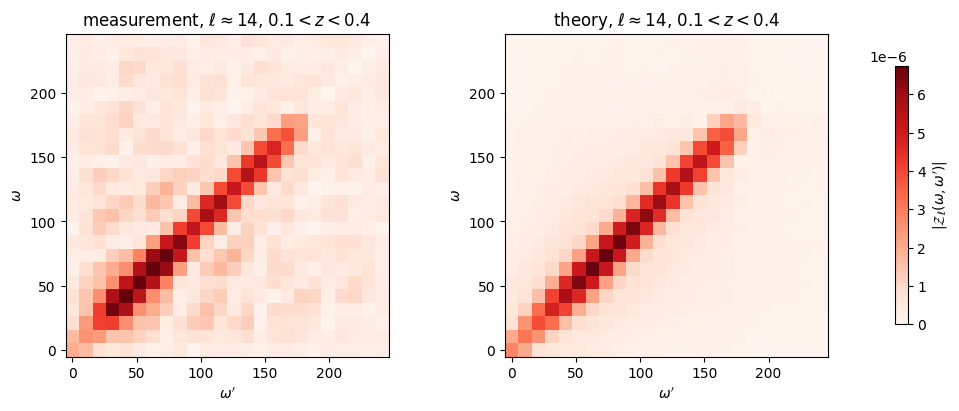

In [20]:
# Define the survey setup (without recomputing the mask and n(z))
pairs = survey.rebin(width=1, pairs=True)
# Compute the cross-power spectra in data and theory
Z_plus_obs, Z_minus_obs = pairs.measure(ra, dec, z)
Z_plus_th, Z_minus_th = pairs.expected(spectra)

# Plot |Z_ell(omega, omega')|
iz = 0 # first z-bin
iell = 1 # ell-bin centered at ell=14
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
vmax = np.abs(Z_plus_th[iz, :, :, iell]).max()
for ax, x, title in zip(axes, (Z_plus_obs, Z_plus_th), ('measurement', 'theory')):
    im = ax.pcolormesh(omega[iz], omega[iz], np.abs(x[iz, :, :, iell]), shading='nearest', cmap='Reds', vmin=0, vmax=vmax)
    ax.set(xlabel=r"$\omega'$", ylabel=r'$\omega$', aspect='equal',
           title=rf'{title}, $\ell \approx {ell[iell]:.0f}$, ${survey.zbins[iz]} < z < {survey.zbins[iz + 1]}$')
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$|\mathcal{Z}_\ell(\omega, \omega')|$")

We can fit models to the off-diagonal power spectrum, similar to before. The covariance of the pairs grows quickly with the number of omega-bins, so for fits it is convenient to bin the spectra in frequency.

In [21]:
pairs3 = survey.rebin(width=3, pairs=True)
fit(pairs3, pairs3.measure(ra, dec, z), spectra)

Redshift bin 0: assigning 499972 galaxies to the grid and transforming to 24 frequencies
Redshift bin 0: computing 48 spherical harmonic transforms and the power spectra
Redshift bin 1: assigning 561655 galaxies to the grid and transforming to 24 frequencies
Redshift bin 1: computing 48 spherical harmonic transforms and the power spectra
Computing the covariance of 4590 elements before omega-binning
A = 1.013 +- 0.025;  chi2 = 4317.9 for 4589 degrees of freedom
